In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/raw/bloomberg/"

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
def load_tenor(tenor):
    d = pd.read_csv(data_path / f"ovdv_impvol/SPX_IMPVOL_{tenor}.csv", parse_dates=True, index_col=0)
    d.columns = d.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
    d.columns.name = "moneyness"
    return d

BAD_DATES = ["2022-09-20"]  # see 01_eda_series, step 2c

# no interpolation: filling t with t+1 would leak the target into the inputs
iv = load_tenor("30DAY")
iv.loc[BAD_DATES] = np.nan
d_iv = iv.diff()

In [4]:
TEST_START = "2021-01-01"
test = iv.index[iv.index >= TEST_START]

y = iv.loc[test]
pred_rw = iv.shift(1).loc[test]

In [5]:
def fit_ar1(s, end, window=None, robust=False):
    df = pd.concat([s, s.shift(1)], axis=1, keys=["y", "x"]).dropna()
    df = df[df.index < end]
    if window:
        df = df.iloc[-window:]
    X = sm.add_constant(df["x"])
    model = sm.RLM(df["y"], X, M=sm.robust.norms.HuberT()) if robust else sm.OLS(df["y"], X)
    return model.fit().params


def predict_ar1(window=None, robust=False):
    """Walk-forward AR(1) on daily changes, refit on the first day of each month."""
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    phi = pd.DataFrame(index=test.to_period("M").unique(), columns=iv.columns, dtype=float)
    for month, days in pd.Series(test, index=test).groupby(test.to_period("M")):
        for m in iv.columns:
            c, b = fit_ar1(d_iv[m], days.index[0], window, robust)
            pred.loc[days.index, m] = iv[m].shift(1).loc[days.index] + c + b * d_iv[m].shift(1).loc[days.index]
            phi.loc[month, m] = b
    return pred, phi

In [6]:
preds = {"persistence": pred_rw}
phis = {}
for name, kw in {
    "ar1_expanding": {},
    "ar1_rolling252": {"window": 252},
    "ar1_huber": {"robust": True},
    "ar1_rolling252_huber": {"window": 252, "robust": True},
}.items():
    preds[name], phis[name] = predict_ar1(**kw)

In [7]:
valid = y.notna().all(axis=1)
for p in preds.values():
    valid &= p.notna().all(axis=1)

errors = {name: (y - p)[valid] for name, p in preds.items()}
print(f"Evaluated days: {valid.sum()} ({y.index[valid][0]:%Y-%m-%d} to {y.index[valid][-1]:%Y-%m-%d})")

Evaluated days: 1444 (2021-01-04 to 2026-10-07)


In [8]:
def r2_oos(e, e_ref):
    return 1 - (e**2).to_numpy().sum() / (e_ref**2).to_numpy().sum()

summary = pd.DataFrame({
    name: {
        "mae": e.abs().to_numpy().mean(),
        "rmse": np.sqrt((e**2).to_numpy().mean()),
        "mae_vs_rw": e.abs().to_numpy().mean() / errors["persistence"].abs().to_numpy().mean() - 1,
        "r2_oos_vs_rw": r2_oos(e, errors["persistence"]),
    }
    for name, e in errors.items()
}).T
summary.round(4)

,mae,rmse,mae_vs_rw,r2_oos_vs_rw
persistence,0.9071,1.4531,0.0000,0.0000
ar1_expanding,0.9230,1.4536,0.0175,-0.0008
ar1_rolling252,0.9029,1.4345,-0.0046,0.0254
ar1_huber,0.9045,1.4398,-0.0029,0.0182
ar1_rolling252_huber,0.8989,1.4361,-0.0091,0.0233


In [9]:
mae_by_moneyness = pd.DataFrame({name: e.abs().mean(axis=0) for name, e in errors.items()})
mae_by_moneyness.round(3)

,persistence,ar1_expanding,ar1_rolling252,ar1_huber,ar1_rolling252_huber
moneyness,,,,,
80.0,1.053,1.063,1.051,1.051,1.046
90.0,0.978,0.985,0.973,0.973,0.969
95.0,0.982,1.001,0.982,0.984,0.977
97.5,0.996,1.017,0.996,0.998,0.992
100.0,0.989,1.009,0.988,0.990,0.984
102.5,0.878,0.902,0.877,0.880,0.872
105.0,0.697,0.724,0.696,0.700,0.693
110.0,0.459,0.492,0.458,0.461,0.456
120.0,1.131,1.114,1.106,1.103,1.101


In [10]:
mae_by_year = pd.DataFrame({name: e.abs().mean(axis=1).groupby(e.index.year).mean() for name, e in errors.items()})
mae_by_year.round(3)

,persistence,ar1_expanding,ar1_rolling252,ar1_huber,ar1_rolling252_huber
date,,,,,
2021,1.024,1.013,1.003,0.999,0.999
2022,1.166,1.228,1.182,1.186,1.169
2023,0.732,0.741,0.728,0.728,0.726
2024,0.710,0.748,0.713,0.725,0.711
2025,0.984,0.985,0.977,0.975,0.976
2026,0.807,0.797,0.793,0.792,0.792


In [11]:
def diebold_mariano(e_ref, e, loss, maxlags=5):
    dl = loss(e_ref).mean(axis=1) - loss(e).mean(axis=1)
    res = sm.OLS(dl.to_numpy(), np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return res.tvalues[0], res.pvalues[0]

losses = {"squared": lambda e: e**2, "absolute": lambda e: e.abs()}
dm = pd.DataFrame({
    (name, loss_name): dict(zip(["t_stat", "p_value"], diebold_mariano(errors["persistence"], e, loss)))
    for name, e in errors.items() if name != "persistence"
    for loss_name, loss in losses.items()
}).T
dm.round(3)

t_stat  p_value
ar1_expanding        squared   -0.030    0.976
                     absolute  -1.768    0.077
ar1_rolling252       squared    1.820    0.069
                     absolute   0.784    0.433
ar1_huber            squared    0.921    0.357
                     absolute   0.384    0.701
ar1_rolling252_huber squared    1.881    0.060
                     absolute   1.710    0.087

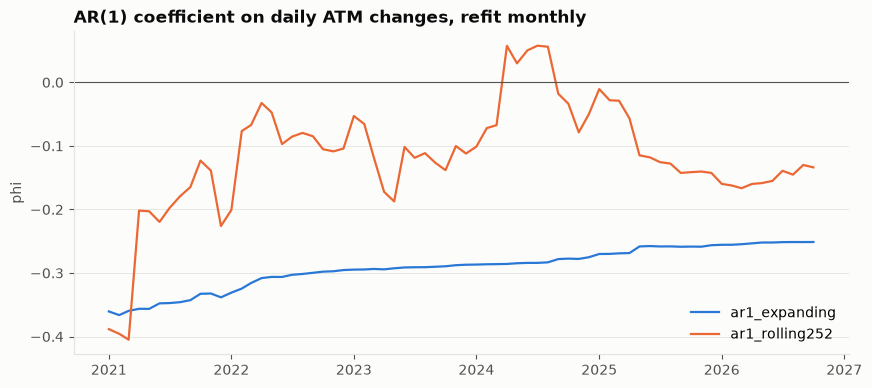

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in zip(["ar1_expanding", "ar1_rolling252"], COLORS):
    phi = phis[name][100.0]
    ax.plot(phi.index.to_timestamp(), phi, color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("AR(1) coefficient on daily ATM changes, refit monthly")
ax.set_ylabel("phi")
ax.legend()
plt.show()

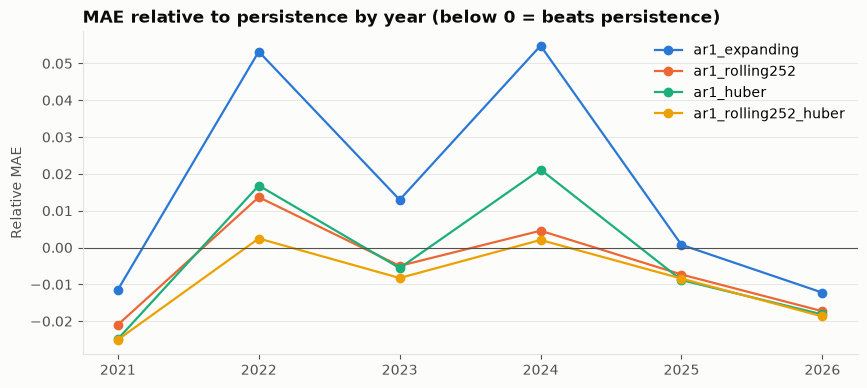

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
rel = mae_by_year.drop(columns="persistence").div(mae_by_year["persistence"], axis=0) - 1
for name, color in zip(rel.columns, COLORS):
    ax.plot(rel.index, rel[name], marker="o", color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("MAE relative to persistence by year (below 0 = beats persistence)")
ax.set_ylabel("Relative MAE")
ax.legend()
plt.show()